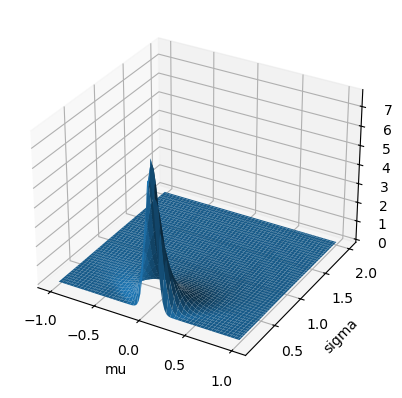

In [4]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

data = np.array([0.2, -0.1, 0.05])

mu = np.linspace(-1, 1, 100)
sigma = np.linspace(0.1, 2, 100)
MU, SIGMA = np.meshgrid(mu, sigma)

Z = np.prod(norm.pdf(data[:, None, None], MU, SIGMA), axis=0)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(MU, SIGMA, Z)

ax.set_xlabel('mu')
ax.set_ylabel('sigma')
ax.set_zlabel('likelihood')

plt.show()


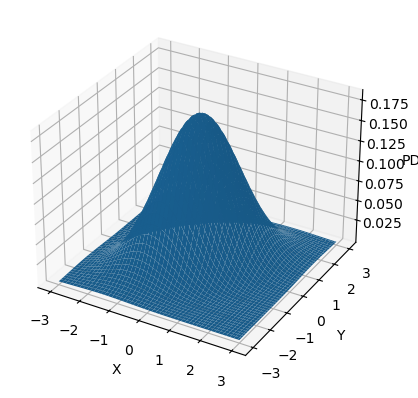

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal

# Grid
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# Bivariate normal
rv = multivariate_normal(mean=[0, 0], cov=[[1, 0.5], [0.5, 1]])
Z = rv.pdf(pos)

# Plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('PDF')

plt.show()


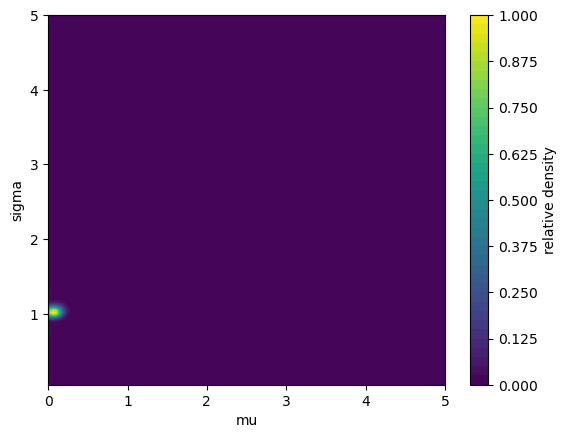

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# "Data" from standard normal
np.random.seed(0)
data = np.random.normal(0, 1, size=200)

# Parameter grid
mu = np.linspace(0, 5, 150)
sigma = np.linspace(0.05, 5, 150)   # avoid sigma=0
MU, SIGMA = np.meshgrid(mu, sigma)

# Log-likelihood
logL = np.sum(
    norm.logpdf(data[:, None, None], MU, SIGMA),
    axis=0
)

# Convert to relative density
logL -= np.max(logL)
Z = np.exp(logL)

# Plot
plt.contourf(MU, SIGMA, Z, levels=40)
plt.colorbar(label="relative density")
plt.xlabel("mu")
plt.ylabel("sigma")
plt.show()



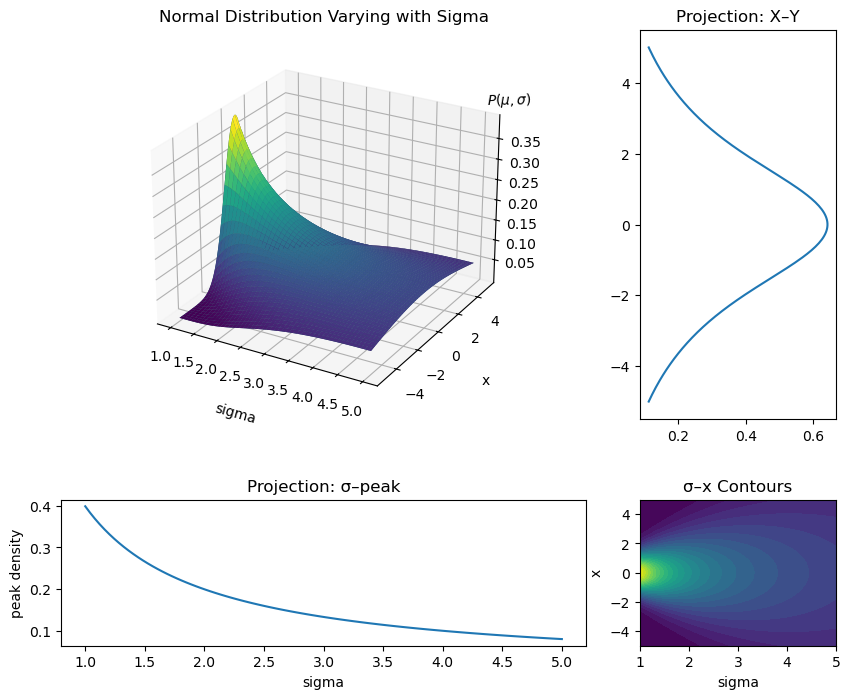

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from matplotlib.gridspec import GridSpec

# Axes
x = np.linspace(-5, 5, 200)
sigma = np.linspace(1, 5, 100)

X, SIGMA = np.meshgrid(x, sigma)
Y = norm.pdf(X, 0, SIGMA)

# --- Projections ---
proj_XY = np.trapz(Y, sigma, axis=0)   # integrate over sigma
proj_SIGY = np.trapz(Y, x, axis=1)     # integrate over x

# --- Layout ---
fig = plt.figure(figsize=(10, 8))
gs = GridSpec(
    2, 2,
    width_ratios=[4, 1.5],
    height_ratios=[4, 1.5],
    wspace=0.15,
    hspace=0.30
)

# --- Main 3D plot ---
ax3d = fig.add_subplot(gs[0, 0], projection="3d")
ax3d.plot_surface(SIGMA, X, Y)
mappable = ax3d.plot_surface(SIGMA, X, Y, cmap="viridis")

ax3d.set_xlabel("sigma", labelpad=10)
ax3d.set_ylabel("x", labelpad=10)
ax3d.text2D(
    0.92, 0.82, r"$P(\mu, \sigma)$",
    transform=ax3d.transAxes,
    rotation=1,
    va="center"
)

ax3d.set_title("Normal Distribution Varying with Sigma")
ax3d.view_init(elev=25, azim=-60)

# --- Right projection: (X, Y) ---
ax_right = fig.add_subplot(gs[0, 1])
ax_right.plot(proj_XY, x)
#ax_right.set_yticks([])
ax_right.set_title("Projection: X–Y")

# --- Bottom projection: (SIGMA, Y) ---
ax_bottom = fig.add_subplot(gs[1, 0])
# Use peak height for convex behavior
peak_density = 1 / (np.sqrt(2 * np.pi) * sigma)
ax_bottom.plot(sigma, peak_density)
ax_bottom.set_xlabel("sigma")
ax_bottom.set_ylabel("peak density")
ax_bottom.set_title("Projection: σ–peak")

# --- Empty cell ---
ax_br = fig.add_subplot(gs[1, 1])
ax_br.contourf(SIGMA, X, Y, levels=30)
ax_br.set_xlabel("sigma")
ax_br.set_ylabel("x")
ax_br.set_title("σ–x Contours")



plt.show()



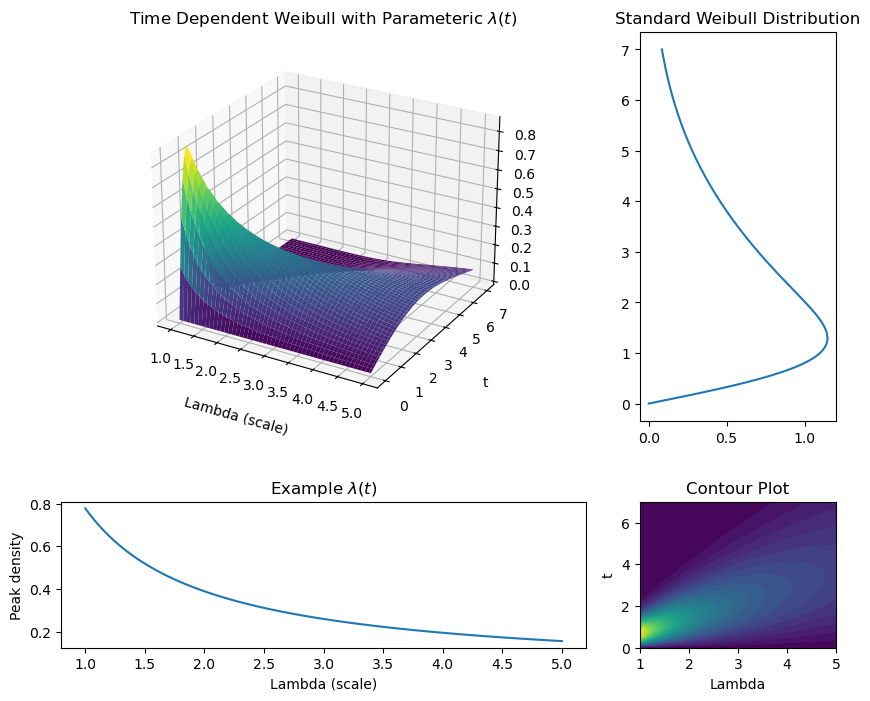

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min
from matplotlib.gridspec import GridSpec

# --- Parameters ---
x = np.linspace(0, 7, 200)        # X axis for Weibull
lambda_vals = np.linspace(1, 5, 100)  # Lambda varying over "time"
k = 2  # fixed shape parameter

# --- Meshgrid ---
X, LAMBDA = np.meshgrid(x, lambda_vals)

# --- Weibull PDF with time-varying scale ---
Y = weibull_min.pdf(X, c=k, scale=LAMBDA)

# --- Projections ---
proj_XY = np.trapz(Y, lambda_vals, axis=0)   # integrate over lambda
proj_LAMBDA_Y = np.trapz(Y, x, axis=1)      # integrate over x

# --- Layout ---
fig = plt.figure(figsize=(10, 8))
gs = GridSpec(
    2, 2,
    width_ratios=[4, 1.5],
    height_ratios=[4, 1.5],
    wspace=0.15,
    hspace=0.30
)

# --- Main 3D plot ---
ax3d = fig.add_subplot(gs[0, 0], projection="3d")
mappable = ax3d.plot_surface(LAMBDA, X, Y, cmap="viridis")
ax3d.set_xlabel("Lambda (scale)", labelpad=10)
ax3d.set_ylabel("t", labelpad=10)
ax3d.set_title(r"Time Dependent Weibull with Parameteric $\lambda(t)$ ")
ax3d.view_init(elev=25, azim=-60)

# --- Right projection: (X, Y) ---
ax_right = fig.add_subplot(gs[0, 1])
ax_right.plot(proj_XY, x)
ax_right.set_title("Standard Weibull Distribution")

# --- Bottom projection: (Lambda, Y) ---
ax_bottom = fig.add_subplot(gs[1, 0])
# Use peak density for convex behavior
peak_density = (k / lambda_vals) * ( ( (k-1)/(k) )**(k-1) ) * np.exp(-( (k-1)/k )**k)  # approx peak
ax_bottom.plot(lambda_vals, peak_density)
ax_bottom.set_xlabel("Lambda (scale)")
ax_bottom.set_ylabel("Peak density")
ax_bottom.set_title(r"Example $\lambda(t)$")

# --- Bottom-right contour ---
ax_br = fig.add_subplot(gs[1, 1])
ax_br.contourf(LAMBDA, X, Y, levels=30, cmap="viridis")
ax_br.set_xlabel("Lambda")
ax_br.set_ylabel("t")
ax_br.set_title("Contour Plot")

plt.savefig("weibull_time_varying_scale.png", dpi=300)
plt.show()
